T2 Vision por computador Jose Quimi

Conversando con el profesor se decidio definir el criterio de clasificacion como persona con telefono, se agrupa en este criterio a todos los que esten usando un telefono de manera directa e indirecta (sosteniendolo o mirando el de otra persona), ademas de los que esten usando el telefono sin mirarlo directamente, de esta manera los negativos corresponderan a las personas que no esten usando un telefono de ninguna manera, ni si quiera sosteniendolo.

Imports


In [6]:
!pip install ultralytics
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from ultralytics import YOLO
import os, fnmatch
import shutil
from google.colab import drive, files
import time

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


## Pre entreno

Pre entrenar modelo con base de datos https://github.com/KvCgRv/FPI-Det/tree/main

In [ ]:

!unzip '/content/drive/MyDrive/reorganized_phone_dataset_yolo.zip'



Streaming output truncated to the last 5000 lines.
  inflating: reorganized_dataset/train/labels/xjzWikd5eLFMQ90sPUab1DJ2flGvgqVp.txt  
  inflating: reorganized_dataset/train/labels/xK3CQEutrXglyhUs67fv5nRmMBjFAkdN.txt  
  inflating: reorganized_dataset/train/labels/Xk7ZShdGv5j2bzF8xicoVID3aWNp1w9B.txt  
  inflating: reorganized_dataset/train/labels/xK86EhWM0bPdCcLUQp2Or1Bi547stIyq.txt  
  inflating: reorganized_dataset/train/labels/xKAiwT4pMrU9nRSQgYBLJ2HEslOIN0kX.txt  
  inflating: reorganized_dataset/train/labels/xkajY54MuhJeIPpRdVTlZCrEWzHSbNoL.txt  
  inflating: reorganized_dataset/train/labels/xKBLQyljEYrMA6uPI2J7U9hpkcWOZN1z.txt  
  inflating: reorganized_dataset/train/labels/xkCENUr3u4MXFLJ2z9ysTjvoAlfGZWOc.txt  
  inflating: reorganized_dataset/train/labels/XkCqL34bwEoQ9MUvZHBpeJ0S78NK1giz.txt  
  inflating: reorganized_dataset/train/labels/xKEX21oTcHJtY7uFvRAZdSmIk6DNb5ny.txt  
  inflating: reorganized_dataset/train/labels/XKFRABQ6nMiw2ZHjVDPsh8OUGLx5mafy.txt  
  inflating: r

In [ ]:
classes = ['Face', 'Phone']
with open('/content/reorganized_dataset/fpi_data.yaml', 'w') as f:
    f.write('path: /content/reorganized_dataset\n')
    f.write('train: train/images\n')
    f.write('val: val/images\n')
    f.write(f'nc: {len(classes)}\n')
    f.write(f'names: {classes}\n')

In [ ]:
pre_train_model = YOLO('yolov8s.pt')
pre_train_model.train(
    data='/content/reorganized_dataset/fpi_data.yaml',
    epochs = 50,
    batch = 16,
    imgsz=640,
    project = '/content/drive/MyDrive/Modelos_YOLO', # para guardar el modelo
    name='pre_train',
    save=True
)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/reorganized_dataset/fpi_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pre_train, nbs=64, nms=None, opset=None, optimi

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b780c8ab700>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## Armar BDD

Armar y descargar bdd


In [ ]:
try:
  shutil.rmtree('data', ignore_errors=True)
  shutil.rmtree('labels', ignore_errors=True)
except Exception as e:
  print(e)
!mkdir labels
!mkdir data
!mkdir data/images
!mkdir data/images/train
!mkdir data/images/val
!mkdir data/images/test
!mkdir data/labels
!mkdir data/labels/train
!mkdir data/labels/val
!mkdir data/labels/test


In [17]:
def dirfiles(img_path,img_ext):
    img_names = fnmatch.filter(sorted(os.listdir(img_path)),img_ext)
    return img_names

# funcion para revisar los bounding box en las imagenes
def print_bounding_boxes(annotation):
    output_path = '/content/drive/MyDrive/bdd_with_bb'

    os.makedirs(output_path, exist_ok=True)

    df = pd.read_csv(annotation)

    for img_path, group in df.groupby('File'):
        print(f'Viendo la imagen {img_path}')
        img_path = os.path.join(save_path, img_path)
        img = cv2.imread(img_path)
        if img is not None:
          for id, row in group.iterrows():
            x1 = int(row['x1'])
            y1 = int(row['y1'])
            x2 = int(row['x2'])
            y2 = int(row['y2'])
            color = (0, 255, 0)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
          nombre_archivo = os.path.basename(img_path)

          out = os.path.join(output_path, nombre_archivo)
          cv2.imwrite(out, img)
        else:
          print(f'La base de datos no concuerda con el CSV: {img_path}')


In [18]:
# Crear la carpeta en drive y guardar
# montar google drive
# drive.mount('/content/drive')
base_path = '/content/drive/MyDrive/2026-T2'
save_path = '/content/drive/MyDrive/BDD_T2_VC'


**!! En caso de reiniciar la carpeta usar el siguiente codigo !!**

In [ ]:
# En caso de reiniciar la carpeta
if os.path.exists(save_path):
  shutil.rmtree(save_path)
  os.makedirs(save_path)
else:
  os.makedirs(save_path)
carpetas = sorted([c for c in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, c))])

for carpeta in carpetas:
  carpeta_path = os.path.join(base_path, carpeta)
  imgs = sorted([img for img in os.listdir(carpeta_path)])

  for i in range(len(imgs)):
    o_path = os.path.join(carpeta_path, imgs[i])
    # prefijo = imgs[i].split('_')[0]
    # imgs[i] = f'{prefijo}_{ct:02d}.png'
    final_path = os.path.join(save_path, imgs[i])
    shutil.copy(o_path, final_path)
    # ct +=1
# En caso de no querer reiniciar la carpeta no ejecutar

In [7]:
# Para descargar desde el archivo zip de imagenes
print(os.getcwd())
archivos = files.upload()
# !unzip '/content/BDD_T2_VC.zip'
# bdd_path = '/content/BDD_T2_VC'

/content


KeyboardInterrupt: 

In [ ]:
# obtener dataframe de las imagenes obtenidas del zip
imagenes =sorted([f for f in os.listdir(bdd_path)], key=lambda x: int(x.split('_')[1].split('.')[0]))
paths = [os.path.join(bdd_path, f) for f in imagenes]
df_paths = pd.DataFrame({'Ruta_imagen': paths})
df_paths

In [19]:
# obtener dataframe de las imagenes en google drive
imagenes = sorted([f for f in os.listdir(save_path)], key=lambda x: int(x.split('_')[1].split('.')[0]))
paths = [os.path.join(save_path, f) for f in imagenes]
df_paths = pd.DataFrame({'Ruta_Imagen': paths})
df_paths

,Ruta_Imagen
0,/content/drive/MyDrive/BDD_T2_VC/fm_000.png
1,/content/drive/MyDrive/BDD_T2_VC/FP_001.png
2,/content/drive/MyDrive/BDD_T2_VC/DB_01.png
3,/content/drive/MyDrive/BDD_T2_VC/AF_001.png
4,/content/drive/MyDrive/BDD_T2_VC/CL_01.png
...,...
2585,/content/drive/MyDrive/BDD_T2_VC/FP_792.png
2586,/content/drive/MyDrive/BDD_T2_VC/FP_793.png
2587,/content/drive/MyDrive/BDD_T2_VC/FP_794.png
2588,/content/drive/MyDrive/BDD_T2_VC/FP_795.png


In [40]:
# obtener csv de anotaciones
# drive.mount('/content/drive', force_remount=True)
#!!! Cargar csv manualmente !!!
csv_path = '/content/CoordenadasT2 - Sheet1.csv'

csv_df = pd.read_csv(csv_path)

csv_df

,File,x1,x2,y1,y2
0,DM_01.png,200,650,130,1000
1,DM_02.png,1,320,90,1000
2,DM_02.png,220,530,200,1000
3,DM_02.png,480,810,95,1000
4,DM_02.png,750,1000,250,1000
...,...,...,...,...,...
2104,AF_018.png,188,484,38,939
2105,AF_019.png,370,966,265,1000
2106,AF_019.png,472,729,190,667
2107,AF_019.png,442,607,190,501


In [41]:
# Dado que se elimino manualmente de la base de datos hay que limpiar el csv para que sea concordante
def eliminate_rows_csv(df, bdd_path):
  for idx in df.index:
    path = df.loc[idx, 'File']
    img_path = os.path.join(bdd_path, path)
    if not os.path.exists(img_path):
      df.drop(idx, inplace=True)
  df.reset_index(drop=True, inplace=True)
  return df



In [42]:
# Para limpiar el csv
csv_df = eliminate_rows_csv(csv_df, save_path)
csv_df

,File,x1,x2,y1,y2
0,DM_01.png,200,650,130,1000
1,DM_02.png,1,320,90,1000
2,DM_02.png,220,530,200,1000
3,DM_02.png,480,810,95,1000
4,DM_02.png,750,1000,250,1000
...,...,...,...,...,...
1882,AF_017.png,416,638,197,924
1883,AF_018.png,188,484,38,939
1884,AF_019.png,370,966,265,1000
1885,AF_019.png,472,729,190,667


In [43]:
# labels
names = dirfiles(save_path, '*.png')
m = len(names)
n = len(csv_df)
# para reiniciar la carpeta de labels
shutil.rmtree('labels')
os.makedirs('labels')

for i in tqdm(range(m)):
  fname = names[i]
  tname = fname[: -4] + '.txt'
  print(fname)
  img = cv2.imread(save_path + '/' + fname)
  N = img.shape[0]
  M = img.shape[1]
  img_con_bb = csv_df[csv_df['File'] == fname]

  txt_path = os.path.join('labels/', tname)
  with open(txt_path, 'w') as f:
    for _, fila in img_con_bb.iterrows():#recorriedno cada fila
      x1 = fila['x1']
      x2 = fila['x2']
      y1 = fila['y1']
      y2 = fila['y2']
      c = 0 # solo hay 1 clase
      wn = (x2 - x1) / M
      hn = (y2 - y1) / N
      xn = ((x1 + x2) / 2) / M
      yn = ((y1 + y2) / 2) / N
      f.write(f'{c} {xn:.6f} {yn:.6f} {wn:.6f} {hn:.6f}\n')


  0%|          | 0/2590 [00:00<?, ?it/s]

AF_001.png
AF_002.png
AF_003.png
AF_004.png
AF_005.png
AF_006.png
AF_007.png
AF_008.png
AF_009.png
AF_010.png
AF_011.png
AF_012.png
AF_013.png
AF_014.png
AF_015.png
AF_016.png
AF_017.png
AF_018.png
AF_019.png
CA_01.png
CA_03.png
CA_04.png
CA_05.png
CA_06.png
CA_07.png
CA_08.png
CA_10.png
CA_11.png
CA_12.png
CA_13.png
CA_14.png
CA_15.png
CA_16.png
CA_17.png
CA_18.png
CA_19.png
CA_20.png
CA_21.png
CA_22.png
CA_23.png
CA_24.png
CA_25.png
CA_26.png
CA_27.png
CA_28.png
CA_29.png
CA_30.png
CA_31.png
CA_32.png
CA_34.png
CA_35.png
CA_36.png
CA_37.png
CA_38.png
CA_39.png
CA_40.png
CA_41.png
CA_42.png
CA_43.png
CA_44.png
CA_45.png
CA_46.png
CA_47.png
CA_48.png
CA_49.png
CA_50.png
CA_51.png
CA_52.png
CA_53.png
CA_54.png
CA_55.png
CA_56.png
CA_57.png
CA_58.png
CA_59.png
CA_60.png
CA_61.png
CA_62.png
CA_63.png
CA_64.png
CA_65.png
CA_67.png
CA_68.png
CA_69.png
CA_70.png
CA_71.png
CA_72.png
CA_73.png
CA_74.png
CA_75.png
CA_76.png
CA_77.png
CA_78.png
CC_01.png
CC_02.png
CC_03.png
CC_04.png
CC_05.png
C

Antes de continuar con la definicion de los subconjuntos de entrenamiento, validacion y testeo, hacer un procesamiento de los datos, revisando de manera manual los datos de entrenamiento del proceso de fine tuning, esta celda no es necesario de ejecutar, ya que se uso para crear una carpeta con las imagenes originales del repositorio comunitario y hacer una seleccion y eliminacion manual de las imagenes.

In [ ]:
#
print_bounding_boxes(csv_path)

Viendo la imagen AF_001.png
Viendo la imagen AF_002.png
Viendo la imagen AF_003.png
Viendo la imagen AF_004.png
Viendo la imagen AF_005.png
Viendo la imagen AF_006.png
Viendo la imagen AF_007.png
Viendo la imagen AF_008.png
Viendo la imagen AF_009.png
Viendo la imagen AF_010.png
Viendo la imagen AF_011.png
Viendo la imagen AF_012.png
Viendo la imagen AF_013.png
Viendo la imagen AF_014.png
Viendo la imagen AF_015.png
Viendo la imagen AF_016.png
Viendo la imagen AF_017.png
Viendo la imagen AF_018.png
Viendo la imagen AF_019.png
Viendo la imagen AF_020.png
La base de datos no concuerda con el CSV: /content/drive/MyDrive/BDD_T2_VC/AF_020.png
Viendo la imagen AS_01.png
Viendo la imagen AS_02.png
Viendo la imagen AS_03.png
Viendo la imagen AS_04.png
Viendo la imagen AS_05.png
Viendo la imagen AS_06.png
Viendo la imagen AS_07.png
Viendo la imagen AS_08.png
Viendo la imagen AS_09.png
Viendo la imagen AS_10.png
Viendo la imagen AS_11.png
Viendo la imagen AS_12.png
Viendo la imagen AS_13.png
Vie

Definir subconjuntos de entrenamiento, validacion y testeo

In [44]:
#
p_train = 0.7 # 70% para entrenamiento
p_val = 0.1 # 10% de validacion

nt = round(p_train * m)
nv = round(p_val * nt)

Mtx = np.vstack([np.zeros((nt-nv,1)),np.ones((nv,1)),2*np.ones((m-nt,1))])
target = ['train','val','test']

for i in tqdm(range(m)):
  fname = names[i]
  tname = fname[:-3]+'txt'
  ti = target[int(Mtx[i])]

  source_path = os.path.join(save_path, fname)
  img_final_path = os.path.join('data/images', ti, fname)

  source_path_label  = os.path.join('labels', tname)
  label_final_path = os.path.join('data/labels', ti, tname)
  # en caso de que la imagen no tenga bb asociado
  if os.path.exists(source_path):
    shutil.copy(source_path, img_final_path)
  shutil.copy(source_path_label, label_final_path)

print('Training: ', nt-nv)
print('     Val: ', nv)
print(' Testing: ',m-nt)

  0%|          | 0/2590 [00:00<?, ?it/s]

/tmp/ipykernel_630/3098757617.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ti = target[int(Mtx[i])]


Training:  1632
     Val:  181
 Testing:  777


## Entrenamiento

Definir archivo YAML

In [25]:
train_path = 'images/train'
val_path = 'images/val'
test_path = 'images/test'
N_C = 1 # 1 clase
class_name = ['Person_with_phone']
f = open('data/data.yaml', 'w+')
f.write('train: ./'+train_path+'\n')
f.write('val:   ./'+val_path+'\n')
f.write('test:  ./'+test_path+'\n')
f.write('nc:  '+str(N_C)+'\n')
f.write('names:  '+str(class_name)+'\n')
f.close()

In [ ]:
# usando el modelo pre entrenado
modelo_pre_entrenado = YOLO('/content/drive/MyDrive/Modelos_YOLO/pre_train/weights/best.pt')
modelo_pre_entrenado.train(
    data='/content/data/data.yaml',
    epochs = 100,
    patience = 10,
    batch = 16,
    imgsz=640,
    freeze = 10,
    lr0= 0.001,
    project='/content/drive/MyDrive/Modelos_fine_tuning',
    name='modelo_fine_tuning_with_patience_with_clean_bdd',
    save=True
)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Modelos_YOLO/pre_train/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=modelo_fine_tun

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7cead7e3b450>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

Definir y entrenar modelo (Solo con la base de datos comunitaria)

In [ ]:
# usando modelo de DL03
YOLO_MODEL     = 'yolov8s'           # can be yolov8n, yolov8m, yolov8l, yolov8x
EPOCHS         = 100
TRAIN_WEIGHTS  = YOLO_MODEL + '.pt'  # pretrained weights
BATCH          = 8
IMG_SIZE       = 640
YAMLFILE       = 'data/data.yaml'    # dataset config
model = YOLO(TRAIN_WEIGHTS)

# Train
model.train(
    data=YAMLFILE,
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMG_SIZE,
    cache=True,
    save=True
)

Tests

In [45]:
pesos_test = '/content/runs/detect/train/weights/best.pt'
pesos_fine_tuning = '/content/drive/MyDrive/Modelos_fine_tuning/modelo_fine_tuning/weights/best.pt'
pesos_fine_tuning_with_patience = '/content/drive/MyDrive/Modelos_fine_tuning/modelo_fine_tuning_with_patience/weights/best.pt'
pesos_fine_tuning_with_patience_with_clean_bdd = '/content/drive/MyDrive/Modelos_fine_tuning/modelo_fine_tuning_with_patience_with_clean_bdd/weights/best.pt'


In [49]:
trained_model = YOLO(pesos_fine_tuning_with_patience_with_clean_bdd)

# Run prediction on your test set
results = trained_model.predict(
    source='/content/data/images/test',
    imgsz=640,
    conf=0.6,
    save=True
)


image 1/777 /content/data/images/test/JL_062.png: 640x640 1 Person_with_phone, 831.3ms
image 2/777 /content/data/images/test/JL_063.png: 640x640 (no detections), 636.9ms
image 3/777 /content/data/images/test/JL_064.png: 640x640 1 Person_with_phone, 616.6ms
image 4/777 /content/data/images/test/JL_065.png: 640x640 1 Person_with_phone, 616.7ms
image 5/777 /content/data/images/test/JL_067.png: 640x640 (no detections), 627.3ms
image 6/777 /content/data/images/test/JL_068.png: 640x640 1 Person_with_phone, 603.9ms
image 7/777 /content/data/images/test/JL_069.png: 640x640 1 Person_with_phone, 619.4ms
image 8/777 /content/data/images/test/JL_070.png: 640x640 (no detections), 624.7ms
image 9/777 /content/data/images/test/JL_071.png: 640x640 1 Person_with_phone, 625.3ms
image 10/777 /content/data/images/test/JL_072.png: 640x640 (no detections), 678.1ms
image 11/777 /content/data/images/test/JL_073.png: 640x640 (no detections), 1109.7ms
image 12/777 /content/data/images/test/JL_074.png: 640x640 

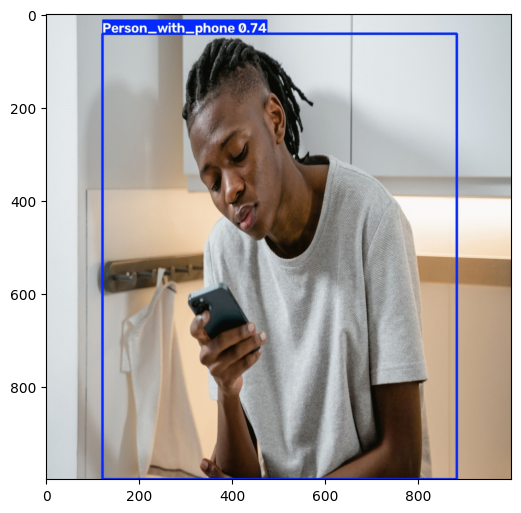

In [31]:
X = cv2.imread('/content/runs/detect/predict/ML_18.jpg')
plt.figure(figsize=(6,8))
plt.imshow(cv2.cvtColor(X, cv2.COLOR_BGR2RGB))
plt.show()

In [ ]:

source = '/content/runs/detect/predict-2'
imagenes_test = [f for f in os.listdir(source)]
paths_test = [os.path.join(source, f) for f in imagenes_test]
df_paths_test = pd.DataFrame({'Ruta_Imagen': paths_test})
# df_paths_test
for idx in df_paths_test.index:
  # print(idx)
  img_path = df_paths_test.loc[idx, 'Ruta_Imagen']
  # print(img_path)
  img = cv2.imread(img_path)
  plt.figure(figsize=(6,8))
  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.show()
  time.sleep(1)
  plt.close()